# Exploratory Data Analysis (EDA)

Simple look at `data/raw/` before writing any pipeline. Expected layout:
`data/raw/<class>/<image files>`.

What we find here decides the cleaning steps in the data prep pipeline.

---
## 0. Library & Configuration

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, UnidentifiedImageError

# Paths (relative to this notebook)
BASE_DIR = Path.cwd().parent
RAW_DIR = BASE_DIR / "data" / "raw"
print(RAW_DIR, RAW_DIR.exists())

d:\project\local-mlops-borrow-kaggle-gpu\mlops-project\data\raw True


---
## 1. What is in `data/raw/`

Folders are classes. Anything else at the top level is not part of the data.

In [2]:
class_dirs = []
other_entries = []
for entry in sorted(RAW_DIR.iterdir()):
    if entry.is_dir():
        class_dirs.append(entry)
    elif entry.name != ".gitkeep":
        other_entries.append(entry.name)

print("Classes:", [d.name for d in class_dirs])
print("Other top-level entries:", other_entries)

Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Other top-level entries: ['LICENSE.txt']


---
## 2. Files per class and extensions

In [3]:
rows = []
for class_dir in class_dirs:
    for path in sorted(class_dir.rglob("*")):
        if path.is_file():
            rows.append(
                {
                    "class": class_dir.name,
                    "path": path,
                    "extension": path.suffix.lower(),
                    "in_subfolder": path.parent != class_dir,
                }
            )

files = pd.DataFrame(rows)
print("Total files:", len(files))
print("Files in nested subfolders:", int(files["in_subfolder"].sum()))
files["extension"].value_counts()

Total files: 3670
Files in nested subfolders: 0


extension
.jpg    3670
Name: count, dtype: int64

class
daisy         633
dandelion     898
roses         641
sunflowers    699
tulips        799
Name: count, dtype: int64
Largest / smallest class: 1.42


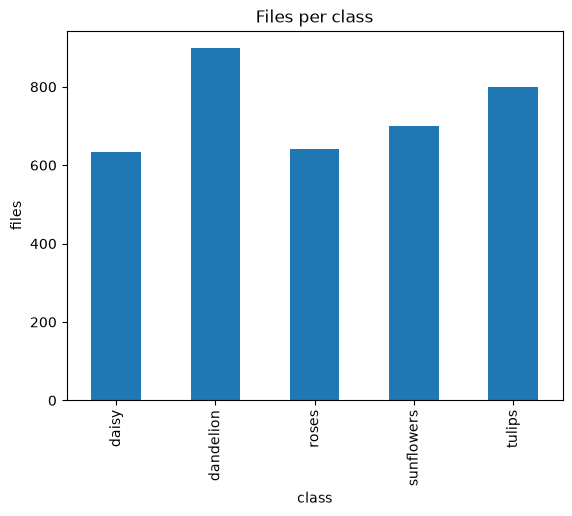

In [4]:
counts = files["class"].value_counts().sort_index()
print(counts)
print("Largest / smallest class:", round(counts.max() / counts.min(), 2))

counts.plot.bar(title="Files per class")
plt.ylabel("files")
plt.show()

---
## 3. Open every file

Readable or not, color mode and size. Takes a while on large datasets.

In [5]:
records = []
for class_name, path in zip(files["class"], files["path"], strict=True):
    record = {
        "class": class_name,
        "path": path,
        "readable": True,
        "mode": None,
        "width": None,
        "height": None,
        "error": None,
    }
    try:
        with Image.open(path) as img:
            img.load()
            record["mode"] = img.mode
            record["width"], record["height"] = img.size
    except (UnidentifiedImageError, OSError) as error:
        record["readable"] = False
        record["error"] = str(error)
    records.append(record)

images = pd.DataFrame(records)
print("Unreadable files:", int((~images["readable"]).sum()))
images.loc[~images["readable"], ["class", "path", "error"]]

Unreadable files: 0


,class,path,error


In [6]:
readable = images[images["readable"]].copy()
readable["mode"].value_counts()

mode
RGB    3670
Name: count, dtype: int64

In [7]:
readable["aspect_ratio"] = readable["width"] / readable["height"]
readable["short_side"] = readable[["width", "height"]].min(axis=1)
readable[["width", "height", "short_side", "aspect_ratio"]].describe().round(2)

,width,height,short_side,aspect_ratio
count,3670.00,3670.00,3670.00,3670.00
mean,365.06,271.79,264.55,1.33
std,116.89,51.74,59.63,0.29
min,143.00,159.00,143.00,0.60
25%,320.00,240.00,219.00,1.26
50%,320.00,240.00,240.00,1.34
75%,500.00,333.00,333.00,1.50
max,1024.00,442.00,442.00,5.48


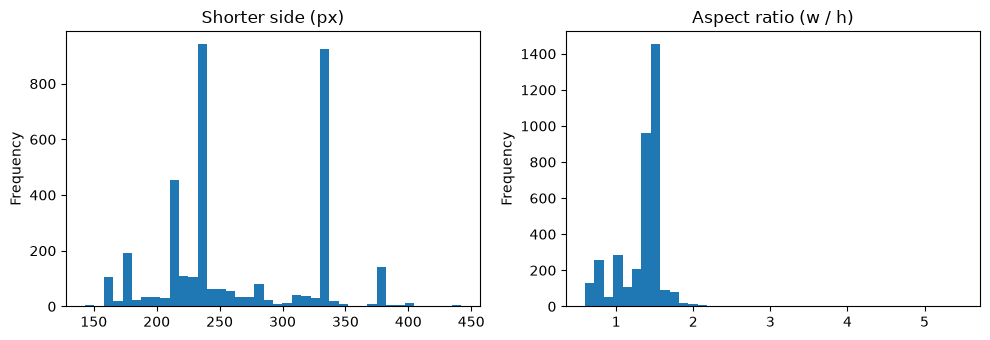

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
readable["short_side"].plot.hist(bins=40, ax=axes[0], title="Shorter side (px)")
readable["aspect_ratio"].plot.hist(bins=40, ax=axes[1], title="Aspect ratio (w / h)")
plt.tight_layout()
plt.show()

In [9]:
# Smallest images: candidates for "too small to use"
readable.sort_values("short_side").head(10)[["class", "path", "width", "height"]]

,class,path,width,height
3087,tulips,d:\project\local-mlops-borrow-kaggle-gpu\mlops...,143,240
3090,tulips,d:\project\local-mlops-borrow-kaggle-gpu\mlops...,145,240
3086,tulips,d:\project\local-mlops-borrow-kaggle-gpu\mlops...,145,240
3083,tulips,d:\project\local-mlops-borrow-kaggle-gpu\mlops...,145,240
785,dandelion,d:\project\local-mlops-borrow-kaggle-gpu\mlops...,146,240
3085,tulips,d:\project\local-mlops-borrow-kaggle-gpu\mlops...,147,240
2815,sunflowers,d:\project\local-mlops-borrow-kaggle-gpu\mlops...,152,240
817,dandelion,d:\project\local-mlops-borrow-kaggle-gpu\mlops...,157,240
3081,tulips,d:\project\local-mlops-borrow-kaggle-gpu\mlops...,157,240
79,daisy,d:\project\local-mlops-borrow-kaggle-gpu\mlops...,158,240


---
## 4. Sample images per class

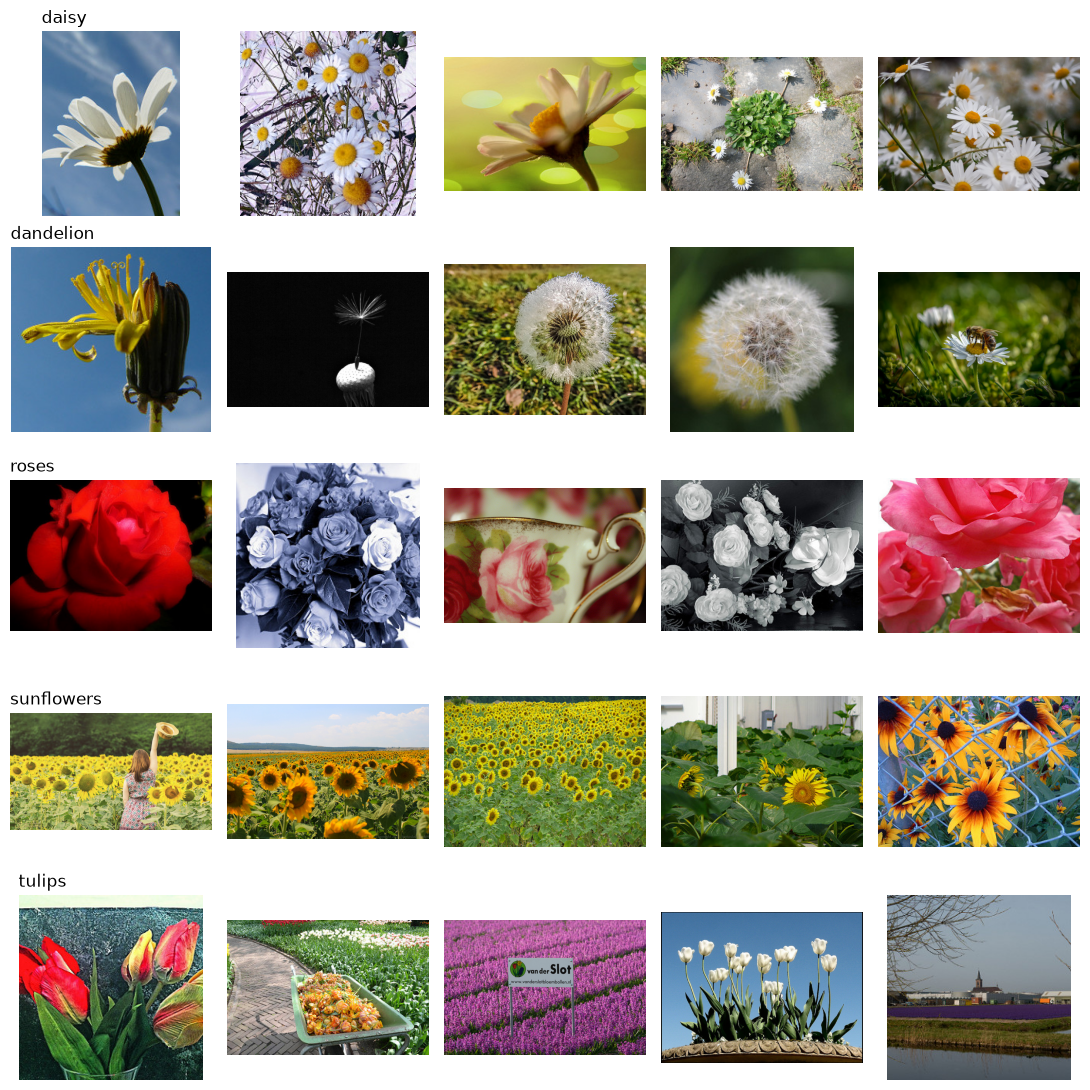

In [ ]:
SAMPLES_PER_CLASS = 5

fig, axes = plt.subplots(
    len(class_dirs),
    SAMPLES_PER_CLASS,
    figsize=(2.2 * SAMPLES_PER_CLASS, 2.2 * len(class_dirs)),
    squeeze=False,
)
for i, class_dir in enumerate(class_dirs):
    class_images = readable[readable["class"] == class_dir.name]
    samples = class_images.sample(
        min(SAMPLES_PER_CLASS, len(class_images)), random_state=42
    )
    for j, path in enumerate(samples["path"]):
        with Image.open(path) as img:
            axes[i][j].imshow(img.convert("RGB"))
    for j in range(SAMPLES_PER_CLASS):
        axes[i][j].axis("off")
    axes[i][0].set_title(class_dir.name, loc="left")
plt.tight_layout()
plt.show()

---
## 5. Findings → cleaning decisions

Flowers (3,670 images, 5 classes):

- Non-image / unexpected files: only `LICENSE.txt` at the top of `data/raw/`. Data prep reads class folders only, so it is skipped automatically.
- Unreadable files: none. The check stays in data prep for users' own data.
- Color modes: 100% RGB. Converting to RGB stays in data prep for users' own data.
- Image sizes: small (median shorter side 240 px, 59% below 256, 27% below 224).
  → `save_size: 224`: shrink the shorter side to 224 only when larger, never upscale, keep the aspect ratio.
  → training `image_size: 224` (ImageNet backbones).
- Class balance: largest / smallest = 1.42, mild.
  → stratified 70/15/15 split with a fixed seed is enough, no class weights.
- A few images have extreme aspect ratios (up to 5.5); center crop cuts part of them. Left as is.
